In [69]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, mean, width):
    return 1.0 / (1 + np.exp(width * (x - mean)))

['../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.72_Ypos104.47600000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.800000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.71499999999999600000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.44999999999999600000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.72_Ypos104.3000000000000100000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.4200000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.72_Ypos104.36600000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.72_Ypos104.54200000.ro

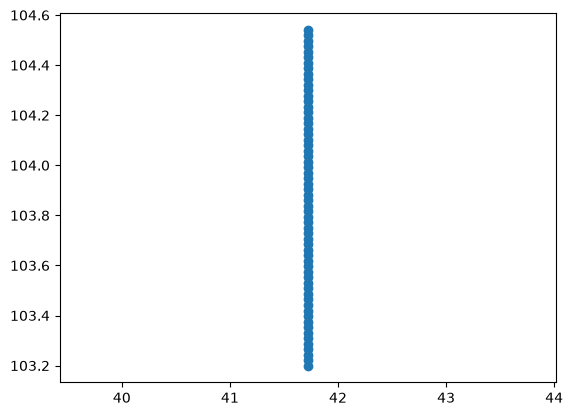

In [70]:
path = "../../Processed_data/"
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")

print(files)
Z_range = [] # [41.5] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 11)
Y_range = [] # np.linspace(41.4, 41.7, 11)

map_plot_y = []
map_plot_x = []
map_plot_z = []

y_files = []

for file in files:
    filename = file.split(path)[1]

    if "Ypos" not in filename: 
        continue

    print(filename)
    y_files.append(file)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.root")[0]), 3)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.trc")[0]), 3)
    # z_pos = np.round(float(filename.split("Zpos")[1].split("_")[0])        , 3)
    
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    X_range.append(float(x_pos))
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    Y_range.append(float(y_pos))
    # x_pos = float(filename.split("Xpos")[1].split("00000.trc")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    Z_range.append(float(z_pos))
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_y)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [71]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(y_files):
    # if map_plot_z[f_i] > 50: continue
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_41.5_41.72_104.476', 'pos_41.5_41.72_104.30000000000001', 'pos_41.5_41.72_104.366', 'pos_41.5_41.72_104.542', 'pos_41.5_41.72_103.486', 'pos_41.5_41.72_104.388', 'pos_41.5_41.72_103.706', 'pos_41.5_41.72_104.01400000000001', 'pos_41.5_41.72_104.12400000000001', 'pos_41.5_41.72_103.926', 'pos_41.5_41.72_103.772', 'pos_41.5_41.72_103.72800000000001', 'pos_41.5_41.72_103.354', 'pos_41.5_41.72_103.552', 'pos_41.5_41.72_104.256', 'pos_41.5_41.72_103.882', 'pos_41.5_41.72_103.464', 'pos_41.5_41.72_103.97', 'pos_41.5_41.72_103.288', 'pos_41.5_41.72_103.596', 'pos_41.5_41.72_103.42', 'pos_41.5_41.72_103.2', 'pos_41.5_41.72_103.816', 'pos_41.5_41.72_104.432', 'pos_41.5_41.72_104.34400000000001', 'pos_41.5_41.72_103.376', 'pos_41.5_41.72_104.45400000000001', 'pos_41.5_41.72_103.244', 'pos_41.5_41.72_104.322', 'pos_41.5_41.72_103.684', 'pos_41.5_41.72_103.44200000000001', 'pos_41.5_41.72_103.33200000000001', 'pos_41.5_41.72_103.53', 'pos_41.5_41.72_104.036', 'pos_41.5_41.72_103.75

[41.5]
pos_41.5_41.72_103.2
pos_41.5_41.72_103.2
len(amp[l][:,0]):  500
31 30 53 33.920716453552245 2.901779239497066
pos_41.5_41.72_103.2
len(amp[l][:,0]):  500
31 30 42 16.454097831726074 2.0643410394848067
pos_41.5_41.72_103.2
len(amp[l][:,0]):  500
31 30 43 7.090532209873199 1.506192490688226
pos_41.5_41.72_103.2
len(amp[l][:,0]):  500
31 30 44 7.575877969741821 1.6450639094150918
pos_41.5_41.72_103.22200000000001
pos_41.5_41.72_103.22200000000001
len(amp[l][:,0]):  500
31 30 45 34.37007808685303 2.9159529499697543
pos_41.5_41.72_103.22200000000001
len(amp[l][:,0]):  500
31 30 40 16.948573219299316 2.1935499195344863
pos_41.5_41.72_103.22200000000001
len(amp[l][:,0]):  500
31 30 42 7.182975095748901 1.5693536799084968
pos_41.5_41.72_103.22200000000001
len(amp[l][:,0]):  500
31 30 48 7.821679675102234 1.7890425464664097
pos_41.5_41.72_103.244
pos_41.5_41.72_103.244
len(amp[l][:,0]):  500
31 30 46 33.07754887008667 2.9219826413956365
pos_41.5_41.72_103.244
len(amp[l][:,0]):  500
31 3

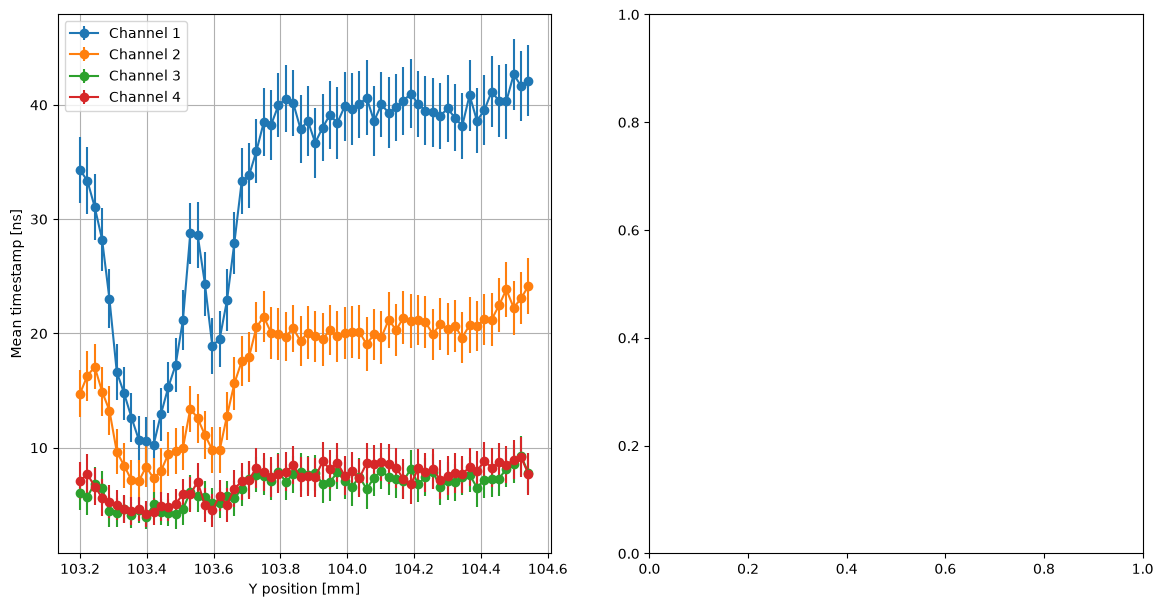

In [95]:
def fit_gaus(hist):
    nbins = 30

    y, x = np.histogram(hist, bins=nbins)
    x = np.array(x)
    y = np.array(y)
    
    mean = x[np.argmax(y)]
    std = np.std(hist)

    mask = (hist>(mean-3*std)) & (hist<(mean+3*std))
    # plt.hist(hist[mask], bins = nbins, histtype="step")
    # plt.show()

    print(len(x), len(y), np.max(y), np.mean(hist), np.std(hist))
    params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=(np.max(y), mean, std))
    return np.max(y), mean, std 
    # return params[0][0], params[0][1], params[0][2]


cols = 2
rows = 1
size = 7

strip_index = 0

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
# Z_range = [50.0, 50.8]
print(Z_range)
for z_i, z in enumerate(Z_range):
    mean_amps_0 = []
    mean_amps_1 = []
    mean_amps_2 = []
    mean_amps_3 = []
    mean_amps_4 = []
    mean_amps_5 = []
    mean_amps_6 = []

    mean_amps_0 = []
    mean_amps_0_err = []
    mean_amps_1 = []
    mean_amps_1_err = []
    mean_amps_2 = []
    mean_amps_2_err = []
    mean_amps_3 = []
    mean_amps_3_err = []

    n_events_0 = []
    n_events_1 = []
    for x_i, x in enumerate(X_range):
        for y_i, y in enumerate(Y_range):
            # l = f"pos_{map_plot_z[z_i]}_{map_plot_x[x_i]}"
            l = f"pos_{z}_{x}_{y}"
            print(l)

            if (len(amp[l][:,0])!=0):
                print(l)
                print("len(amp[l][:,0]): ", len(amp[l][:,0]))
                A, mean, sigma = fit_gaus(amp[l][:,0])
                mean_amps_0.append(mean)
                mean_amps_0_err.append(sigma)
            else:
                mean_amps_0.append(0)
                mean_amps_0_err.append(0)

            if (len(amp[l][:,1])!=0):
                print(l)
                print("len(amp[l][:,0]): ", len(amp[l][:,1]))
                A, mean, sigma = fit_gaus(amp[l][:,1])
                mean_amps_1.append(mean)
                mean_amps_1_err.append(sigma)
            else:
                mean_amps_1.append(0)
                mean_amps_1_err.append(0)

            if (len(amp[l][:,2])!=0):
                print(l)
                print("len(amp[l][:,0]): ", len(amp[l][:,2]))
                A, mean, sigma = fit_gaus(amp[l][:,2])
                mean_amps_2.append(mean)
                mean_amps_2_err.append(sigma)
            else:
                mean_amps_2.append(0)
                mean_amps_2_err.append(0)

            if (len(amp[l][:,3])!=0):
                print(l)
                print("len(amp[l][:,0]): ", len(amp[l][:,3]))
                A, mean, sigma = fit_gaus(amp[l][:,3])
                mean_amps_3.append(mean)
                mean_amps_3_err.append(sigma)
            else:
                mean_amps_3.append(0)
                mean_amps_3_err.append(0)

            # try:
            #     # print(z, x)
            #     mean_amps_0.append(np.mean(timestamps[l][:,0][timestamps[l][:,0]>0]))
            #     mean_amps_1.append(np.mean(timestamps[l][:,1][timestamps[l][:,1]>0]))
            #     mean_amps_2.append(np.mean(timestamps[l][:,2][timestamps[l][:,2]>0]))
            #     mean_amps_3.append(np.mean(timestamps[l][:,3][timestamps[l][:,3]>0]))
            #     mean_amps_4.append(np.mean(timestamps[l][:,4][timestamps[l][:,4]>0]))
            #     mean_amps_5.append(np.mean(timestamps[l][:,5][timestamps[l][:,5]>0]))
            #     mean_amps_6.append(np.mean(timestamps[l][:,6][timestamps[l][:,6]>0]))
            #     n_events_0.append(np.sum(timestamps[l][:,0]>0))
            #     n_events_1.append(np.sum(timestamps[l][:,1]>0))
            #     # print(l, mean_amps[-1]) # , n_events[-1])
            # except:
            #     # print(f"{l} is not ready or taken yet")
            #     mean_amps_0.append(0)
            #     mean_amps_1.append(0)
            #     mean_amps_2.append(0)
            #     mean_amps_3.append(0)
            #     mean_amps_4.append(0)
            #     mean_amps_5.append(0)
            #     mean_amps_6.append(0)
            #     n_events_0.append(0)
            #     n_events_1.append(0)
        
        sorting = np.argsort(Y_range)
        mean_amps_0 = np.array(mean_amps_0)[sorting]
        mean_amps_1 = np.array(mean_amps_1)[sorting]
        mean_amps_2 = np.array(mean_amps_2)[sorting]
        mean_amps_3 = np.array(mean_amps_3)[sorting]
        mean_amps_0_err = np.array(mean_amps_0_err)[sorting]
        mean_amps_1_err = np.array(mean_amps_1_err)[sorting]
        mean_amps_2_err = np.array(mean_amps_2_err)[sorting]
        mean_amps_3_err = np.array(mean_amps_3_err)[sorting]
        # mean_amps_0 = np.array(mean_amps_0)[sorting]
        # mean_amps_1 = np.array(mean_amps_1)[sorting]
        # mean_amps_2 = np.array(mean_amps_2)[sorting]
        # mean_amps_3 = np.array(mean_amps_3)[sorting]
        # mean_amps_4 = np.array(mean_amps_4)[sorting]
        # mean_amps_5 = np.array(mean_amps_5)[sorting]
        # mean_amps_6 = np.array(mean_amps_6)[sorting]
        Y_range = np.array(Y_range)
        Y_range = Y_range[sorting]

        n_events_0 = np.array(n_events_0)
        n_events_1 = np.array(n_events_1)

        # print(X_range[mean_amps != 0])
        # print(mean_amps[mean_amps != 0])
        marker_size = 5
        # ax[0].scatter(Y_range, mean_amps_0, marker_size, label = "Channel 1") # f"Z position: {z}")
        # ax[0].scatter(Y_range, mean_amps_1, marker_size, label = "Channel 2") # f"Z position: {z}")
        # ax[0].scatter(Y_range, mean_amps_2, marker_size, label = "Channel 3") # f"Z position: {z}")
        # ax[0].scatter(Y_range, mean_amps_3, marker_size, label = "Channel 4") # f"Z position: {z}")
        # ax[0].scatter(Y_range, mean_amps_4, marker_size, label = "Channel 5") # f"Z position: {z}")
        # ax[0].scatter(Y_range, mean_amps_5, marker_size, label = "Channel 6") # f"Z position: {z}")
        # ax[0].scatter(Y_range, mean_amps_6, marker_size, label = "Channel 7") # f"Z position: {z}")

        # ax[0].plot(Y_range, mean_amps_0, label = "Channel 1", marker= "o") # f"Z position: {z}")
        # ax[0].plot(Y_range, mean_amps_1, label = "Channel 2", marker= "o") # f"Z position: {z}")
        # ax[0].plot(Y_range, mean_amps_2, label = "Channel 3", marker= "o") # f"Z position: {z}")
        # ax[0].plot(Y_range, mean_amps_3, label = "Channel 4", marker= "o") # f"Z position: {z}")
        # ax[0].plot(Y_range, mean_amps_4, label = "Channel 5", marker= "o") # f"Z position: {z}")
        # ax[0].plot(Y_range, mean_amps_5, label = "Channel 6", marker= "o") # f"Z position: {z}")
        # ax[0].plot(Y_range, mean_amps_6, label = "Channel 7", marker= "o") # f"Z position: {z}")

        ax[0].errorbar(Y_range, mean_amps_0, mean_amps_0_err, label = "Channel 1", marker= "o") # f"Z position: {z}")
        ax[0].errorbar(Y_range, mean_amps_1, mean_amps_1_err, label = "Channel 2", marker= "o") # f"Z position: {z}")
        ax[0].errorbar(Y_range, mean_amps_2, mean_amps_2_err, label = "Channel 3", marker= "o") # f"Z position: {z}")
        ax[0].errorbar(Y_range, mean_amps_3, mean_amps_3_err, label = "Channel 4", marker= "o") # f"Z position: {z}")
        
        ax[0].set_xlabel("Y position [mm]")
        ax[0].set_ylabel("Mean timestamp [ns]")
        # ax[0].set_ylim(0, 200)
        # ax[0].set_xlim(103.8, 104.6)

        # try:
        # mask = (mean_amps != 0) #  & (mean_amps > 41.4) & (mean_amps < 41.7)
        # print(np.sum(mask))
        # if (np.sum(mask) == 0): continue
        # params = curve_fit(sigmoid, X_range[mask], mean_amps[mask], p0 = (np.mean(X_range), 0.1))
        # print(np.mean(X_range), params[0])
        # sigmoid_y = [sigmoid(i, params[0][0], params[0][1]) for i in X_range]
        # print(sigmoid_y)
        # ax[0].plot(X_range, sigmoid_y, label = f"Z position: {z}")
        # print()

        # ax[1].plot(X_range, n_events, label = f"Z position: {z}")
        # ax[1].set_xlabel("X position [mm]")
        # ax[1].set_ylabel("Number of events")
ax[0].grid()
ax[0].legend()
plt.show()

In [79]:
print(len(X_range), len(mean_amps_0), len(mean_amps_0_err))

1 62 62


103.2 24.082293
103.222 23.13878
103.244 20.833023
103.266 17.995924
103.288 12.811821
103.31 6.401922
103.332 4.5286827
103.354 2.4180517
103.376 0.4657421
103.398 0.3608017
103.42 0.0
103.442 2.69915
103.464 5.0549946
103.486 7.0157337
103.508 10.94577
103.53 18.53514
103.552 18.398893
103.574 14.082708
103.596 8.680817
103.618 9.300247
103.64 12.688528
103.662 17.724146
103.684 23.106165
103.706 23.602339
103.728 25.746187
103.75 28.259996
103.772 28.034029
103.794 29.764917
103.816 30.316626
103.838 29.955439
103.86 27.667418
103.882 28.36955
103.904 26.455973
103.926 27.791662
103.948 28.906496
103.97 28.187391
103.992 29.64643
104.014 29.427126
104.036 29.825937
104.058 30.41414
104.08 28.35261
104.102 29.813719
104.124 29.07791
104.146 29.557165
104.168 30.136652
104.19 30.764208
104.212 29.861639
104.234 29.272345
104.256 29.130442
104.278 28.808142
104.3 29.46424
104.322 28.657366
104.344 27.931917
104.366 30.639658
104.388 28.388605
104.41 29.299913
104.432 30.946882
104.454 

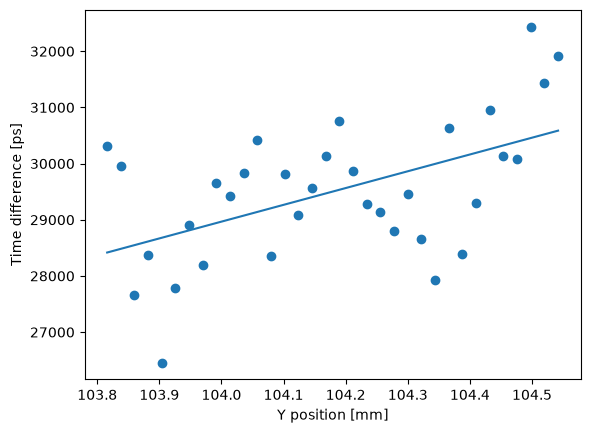

In [96]:
def line(x, p1, p2):
    return x*p1 + p2

def pol_2(x, p1, p2, p3):
    return p1*x**2 + p2*x + p3

def pol_3(x, p1, p2, p3, p4):
    return p1*x**3 + p2*x**2 + p3*x + p4

MT = mean_amps_0
t0 = np.min(MT)
dt = []
for i, t in enumerate(MT):
    dt.append((t - t0)*1000)
    print(np.round(Y_range[i], 4), t - t0)
Y_range = np.array(Y_range)
dt = np.array(dt)

mask = ((Y_range>103.8) & (Y_range<104.6))
params = curve_fit(line, Y_range[mask], dt[mask])


fitted_dt = np.array([line(y, params[0][0], params[0][1]) for y in Y_range])
plt.scatter(Y_range[mask], dt[mask])
plt.plot(Y_range[mask], fitted_dt[mask])
plt.xlim()
plt.xlabel("Y position [mm]")
plt.ylabel("Time difference [ps]")
plt.show()